# Bland–Altman Plot

**Family:** Scientific & clinical &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Scientific & clinical:* Specialised plots for statistics, biomedical research and model evaluation.

## Design purpose

Plots the difference between two measurement methods against their mean, with lines for the mean bias and the 95% limits of agreement. It answers whether two methods agree well enough to be interchangeable, which a correlation coefficient cannot.

## When to use

- Compare a new measurement device or assay with a reference standard
- Assess inter-rater or test–retest agreement on a continuous scale
- Detect proportional bias, where the difference grows with magnitude

## Avoid when

- Measurements are categorical (use Cohen's kappa or a confusion matrix)
- The goal is prediction rather than agreement (use a scatter plot with regression)

## Alternatives

- Scatter plot with identity line
- Passing–Bablok / Deming regression plot

## Design tips

- Label the bias and both limits of agreement directly on the plot
- A trend in the cloud means proportional bias; consider plotting percent differences

## Example

Systolic blood pressure measured in 150 patients with a cuff device (A) and an arterial line (B).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(9)
true_sbp = rng.normal(128, 18, 150)
method_a = true_sbp + rng.normal(0, 4, 150)
method_b = true_sbp + 3 + 0.06 * (true_sbp - 128) + rng.normal(0, 5, 150)
df = pd.DataFrame({"cuff": method_a.round(1), "arterial": method_b.round(1)})
df["mean"] = (df.cuff + df.arterial) / 2
df["diff"] = df.arterial - df.cuff
bias, sd = df["diff"].mean(), df["diff"].std(ddof=1)
loa = (bias - 1.96 * sd, bias + 1.96 * sd)
print(f"bias = {bias:.2f} mmHg, limits of agreement = {loa[0]:.2f} to {loa[1]:.2f}")
df.head()

bias = 2.99 mmHg, limits of agreement = -10.44 to 16.42


,cuff,arterial,mean,diff
0,108.2,118.3,113.25,10.1
1,134.1,131.4,132.75,-2.7
2,95.2,99.6,97.40,4.4
3,140.7,146.1,143.40,5.4
4,153.6,155.9,154.75,2.3


### Plot

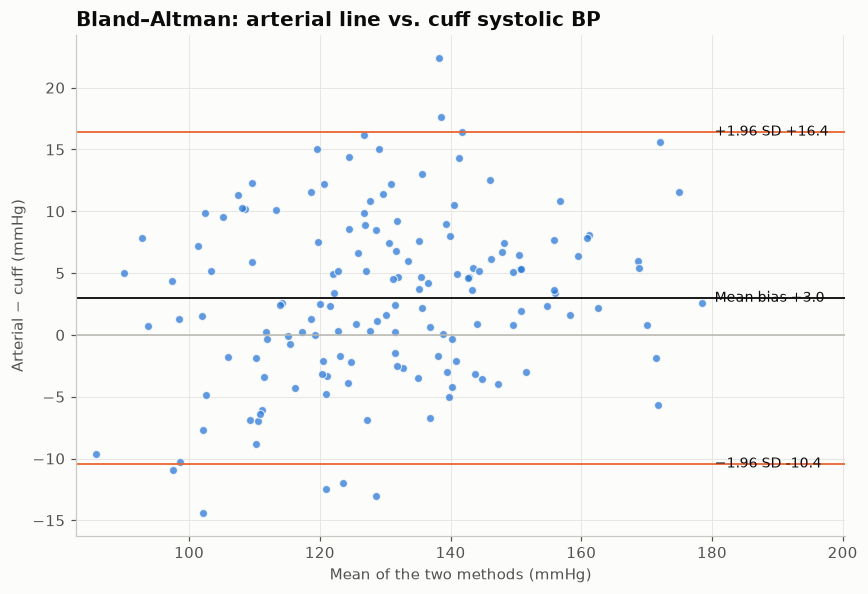

In [3]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(df["mean"], df["diff"], s=28, color=PALETTE[0], alpha=0.75,
           edgecolor="#fcfcfb", linewidth=0.8)
ax.axhline(0, color=GRAY, linewidth=1)
ax.axhline(bias, color="#0b0b0b", linewidth=1.2)
for v in loa:
    ax.axhline(v, color=PALETTE[1], linewidth=1.2)
x_lab = df["mean"].max() + 2
for v, lab in [(bias, f"Mean bias {bias:+.1f}"), (loa[1], f"+1.96 SD {loa[1]:+.1f}"),
               (loa[0], f"−1.96 SD {loa[0]:+.1f}")]:
    ax.text(x_lab, v, lab, va="center", fontsize=9, color="#0b0b0b")
ax.set_xlim(df["mean"].min() - 3, df["mean"].max() + 22)
ax.set_xlabel("Mean of the two methods (mmHg)")
ax.set_ylabel("Arterial − cuff (mmHg)")
ax.set_title("Bland–Altman: arterial line vs. cuff systolic BP")
fig.tight_layout()
plt.show()

## How to read it

On average the arterial line reads about 3 mmHg higher (the bias). In 95% of patients, the two methods differ by no more than the orange limits. The slight upward slope reveals proportional bias.

---
Standalone script: [`bland_altman.py`](bland_altman.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)